In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_sample_weight

In [11]:
covtype = fetch_covtype()

X = pd.DataFrame(covtype.data, columns=covtype.feature_names)
y = pd.Series(covtype.target, name='Cover_Type')

print(f'X shape: {X.shape}')

X shape: (581012, 54)


Pobieranie danych...

--- Basic Informatio ---
Rows: 581012, Columns: 55
Missing values: 0
Duplicates: 0

--- Class Distribution (Targets) ---
Cover_Type
1    36.46 %
2    48.76 %
3     6.15 %
4     0.47 %
5     1.63 %
6     2.99 %
7     3.53 %
Name: proportion, dtype: object


C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_8448\4234368329.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Cover_Type', palette='viridis')


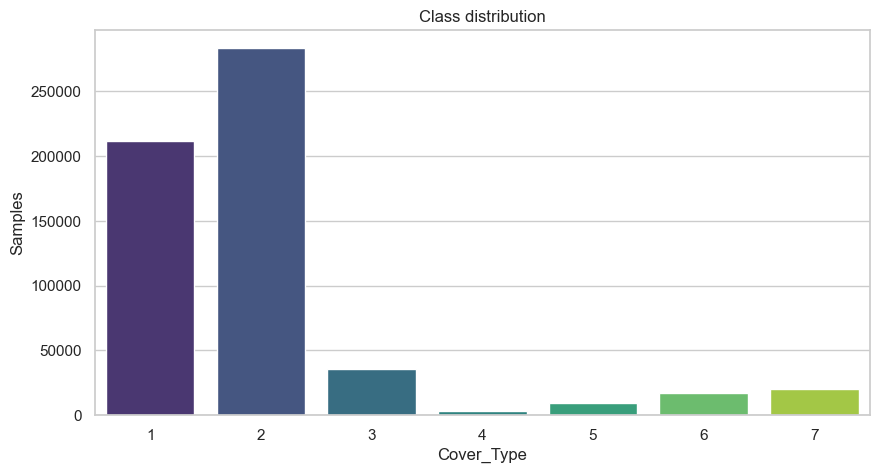


--- Continuous Variables  ---


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
count,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00,581012.00
mean,2959.37,155.66,14.10,269.43,46.42,2350.15,212.15,223.32,142.53,1980.29
std,279.98,111.91,7.49,212.55,58.30,1559.25,26.77,19.77,38.27,1324.20
min,1859.00,0.00,0.00,0.00,-173.00,0.00,0.00,0.00,0.00,0.00
25%,2809.00,58.00,9.00,108.00,7.00,1106.00,198.00,213.00,119.00,1024.00
50%,2996.00,127.00,13.00,218.00,30.00,1997.00,218.00,226.00,143.00,1710.00
75%,3163.00,260.00,18.00,384.00,69.00,3328.00,231.00,237.00,168.00,2550.00
max,3858.00,360.00,66.00,1397.00,601.00,7117.00,254.00,254.00,254.00,7173.00


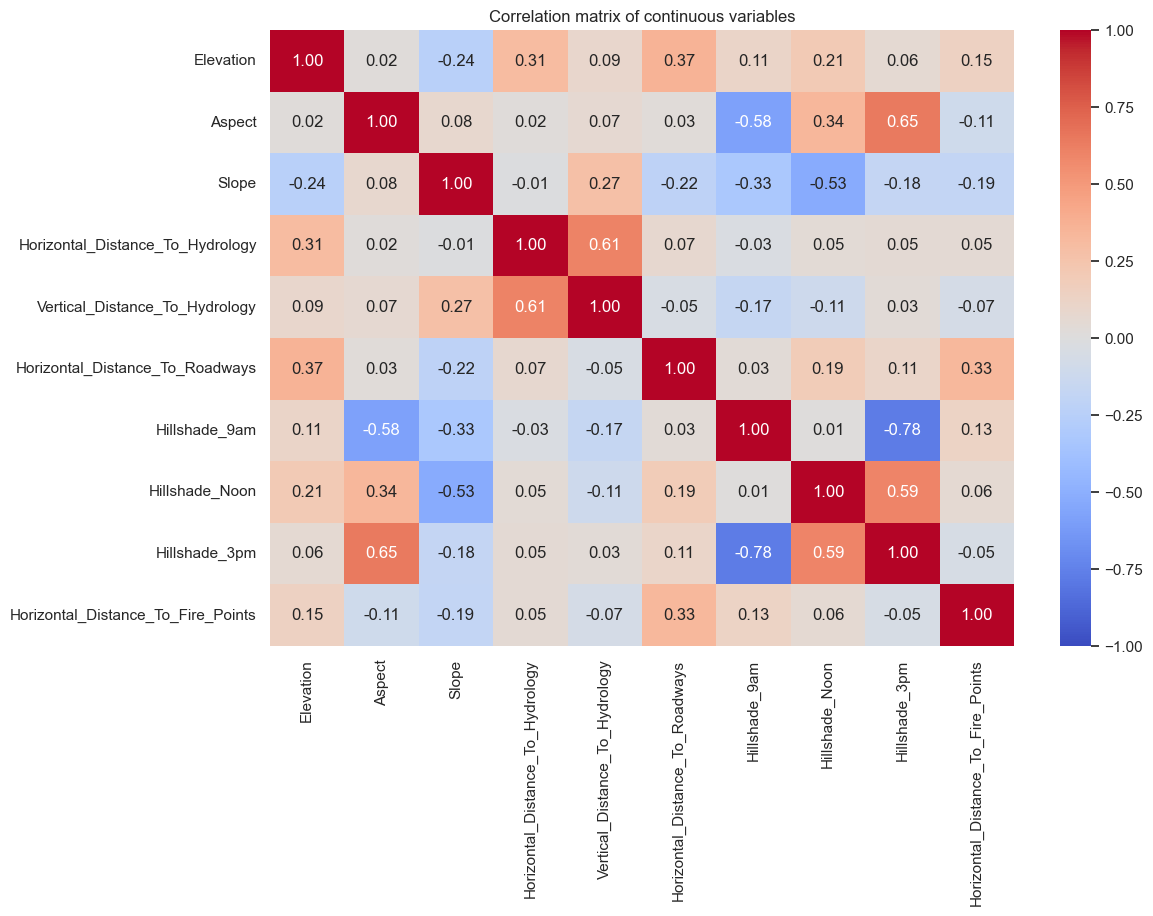

C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_8448\4234368329.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sample, x='Cover_Type', y=col, ax=axes[i], palette='muted')
C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_8448\4234368329.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sample, x='Cover_Type', y=col, ax=axes[i], palette='muted')
C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_8448\4234368329.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sample, x='Cover_Type', y=col, ax=axes[i], pal

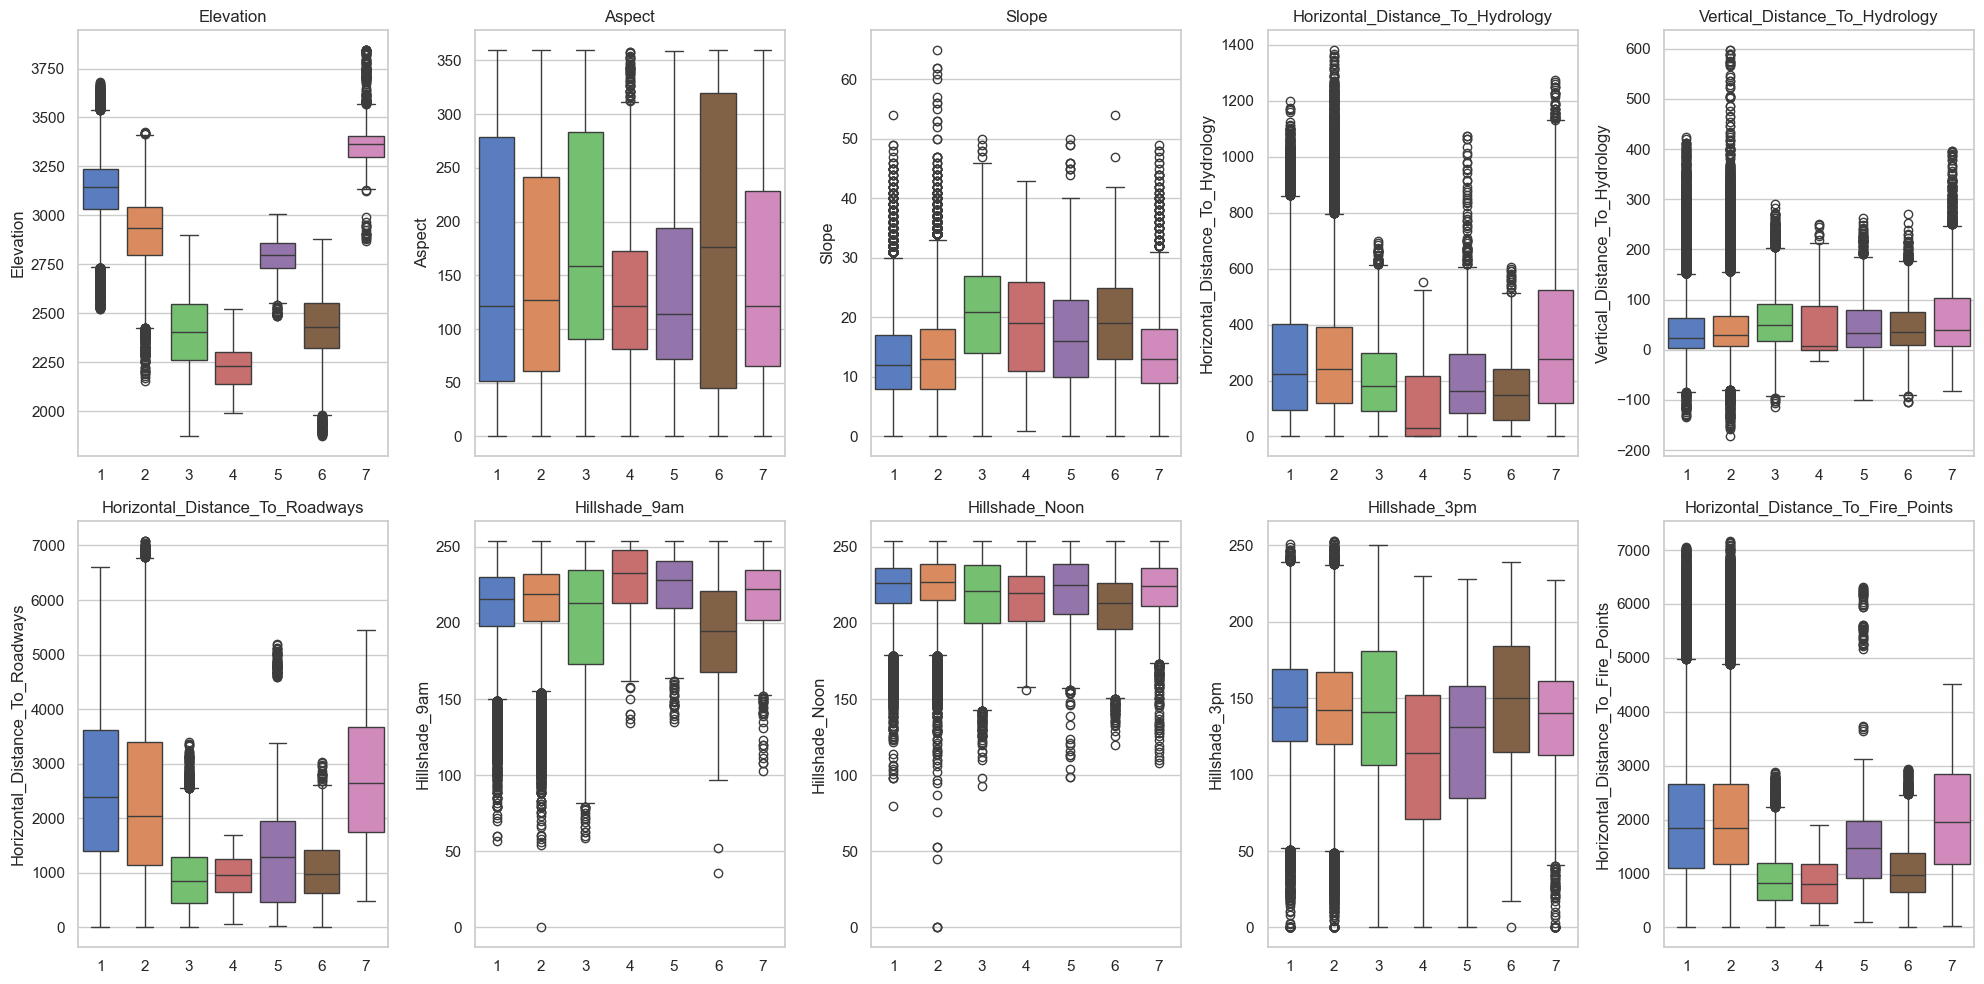


--- Analysing Land and Soil ---


C:\Users\Eryk Orzech\AppData\Local\Temp\ipykernel_8448\4234368329.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Wilderness_Category', palette='Set2')


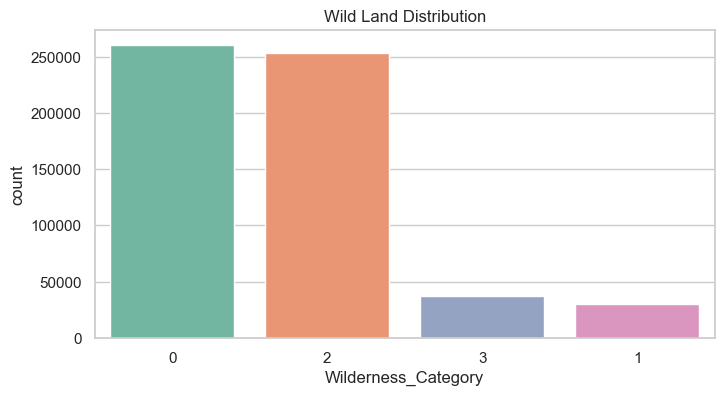

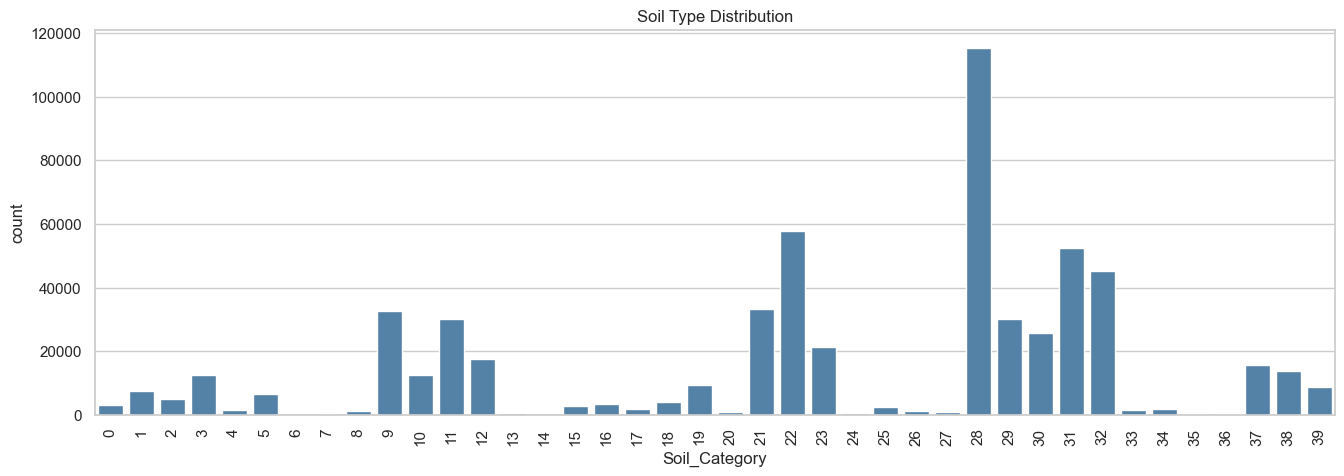

Amount of types of soil, being less than 0.01% of dataset: 6
[24, 36, 7, 35, 6, 14]


In [12]:
# Plot type
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Pobieranie danych...")
covtype = fetch_covtype()
df = pd.DataFrame(covtype.data, columns=covtype.feature_names)
df['Cover_Type'] = covtype.target

# Grouping features
num_cols = df.columns[:10].tolist()         # First 10 are numerical
wild_cols = [c for c in df.columns if 'Wilderness_Area' in c]
soil_cols = [c for c in df.columns if 'Soil_Type' in c]

print(f"\n--- Basic Informatio ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicates: {df.duplicated().sum()}") 

# 2. Class distribution
print("\n--- Class Distribution (Targets) ---")
class_dist = df['Cover_Type'].value_counts(normalize=True).sort_index() * 100
print(class_dist.round(2).astype(str) + ' %')

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Cover_Type', palette='viridis')
plt.title('Class distribution')
plt.ylabel('Samples')
plt.show()

print("\n--- Continuous Variables  ---")
display(df[num_cols].describe().round(2))

# Continuous variable distribution
plt.figure(figsize=(12, 8))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation matrix of continuous variables')
plt.show()

# How does numerical variables behave for particular class?
# We use sample of 100k rows
df_sample = df.sample(n=100000, random_state=42)

fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(data=df_sample, x='Cover_Type', y=col, ax=axes[i], palette='muted')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
plt.tight_layout()
plt.show()

# Analysing categorical variables (Reverse One-Hot Encoding)
# We check which type of soil and wild lands dominate
print("\n--- Analysing Land and Soil ---")
df['Wilderness_Category'] = df[wild_cols].idxmax(axis=1).str.replace('Wilderness_Area_', '')
df['Soil_Category'] = df[soil_cols].idxmax(axis=1).str.replace('Soil_Type_', '').astype(int)

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Wilderness_Category', palette='Set2')
plt.title('Wild Land Distribution')
plt.show()

plt.figure(figsize=(16, 5))
sns.countplot(data=df, x='Soil_Category', color='steelblue')
plt.title('Soil Type Distribution')
plt.xticks(rotation=90)
plt.show()

# Looking for rare types of soil
soil_freq = df['Soil_Category'].value_counts(normalize=True)
rare_soils = soil_freq[soil_freq < 0.001]
print(f"Amount of types of soil, being less than 0.01% of dataset: {len(rare_soils)}")
print(rare_soils.index.tolist())

In [13]:
covtype = fetch_covtype()
df = pd.DataFrame(covtype.data, columns=covtype.feature_names)
df['Cover_Type'] = covtype.target

df = df.drop_duplicates()

df['Distance_To_Hydrology'] = np.sqrt(
    df['Horizontal_Distance_To_Hydrology']**2 + df['Vertical_Distance_To_Hydrology']**2
)
df['Elevation_Minus_Vertical_Hydrology'] = df['Elevation'] - df['Vertical_Distance_To_Hydrology']
df['Elevation_Plus_Vertical_Hydrology'] = df['Elevation'] + df['Vertical_Distance_To_Hydrology']

df['Hillshade_9am_Minus_3pm'] = df['Hillshade_9am'] - df['Hillshade_3pm']
df['Hillshade_Noon_Minus_3pm'] = df['Hillshade_Noon'] - df['Hillshade_3pm']
df['Mean_Hillshade'] = (df['Hillshade_9am'] + df['Hillshade_Noon'] + df['Hillshade_3pm']) / 3

df['Mean_Distance_To_Amenities'] = (
    df['Horizontal_Distance_To_Fire_Points'] + df['Horizontal_Distance_To_Roadways']
) / 2

X = df.drop(columns=['Cover_Type'])
y = df['Cover_Type'] - 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [14]:
sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

xgb_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=7,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train, 
    y_train, 
    sample_weight=sample_weights
)

y_pred = xgb_model.predict(X_test)

print("Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

Classification Report:

              precision    recall  f1-score   support

           0     0.8445    0.8588    0.8516     42368
           1     0.9042    0.8174    0.8586     56661
           2     0.8880    0.9195    0.9035      7151
           3     0.8018    0.9581    0.8730       549
           4     0.4189    0.9784    0.5867      1899
           5     0.7309    0.9410    0.8228      3473
           6     0.8238    0.9902    0.8994      4102

    accuracy                         0.8519    116203
   macro avg     0.7732    0.9233    0.8279    116203
weighted avg     0.8650    0.8519    0.8548    116203

